# ASHRAE energy prediction
Download the six competition CSVs with KaggleHub and load them into pandas. If Kaggle requests authentication, run `kagglehub.login()` and accept the competition rules on Kaggle before retrying.

In [1]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# if u r working from google colab

# # Import datasets
# building_metadata = pd.read_csv("/content/building_metadata.csv")
# sample_submission = pd.read_csv("/content/sample_submission.csv")
# test = pd.read_csv("/content/test.csv")
# train = pd.read_csv("/content/train.csv")
# weather_test = pd.read_csv("/content/weather_test.csv")
# weather_train = pd.read_csv("/content/weather_train.csv")

# train.head()

,building_id,meter,timestamp,meter_reading
0,0,0,2016-01-01 00:00:00,0.0
1,1,0,2016-01-01 00:00:00,0.0
2,2,0,2016-01-01 00:00:00,0.0
3,3,0,2016-01-01 00:00:00,0.0
4,4,0,2016-01-01 00:00:00,0.0


In [8]:
# if u r working from VS Code

# Define dataset directory 
path = Path(r"C:\Users\PC\iCloudDrive\GA\ashare-energy-prediction-dataset")

# Import datasets
building_metadata = pd.read_csv(path / "building_metadata.csv")
sample_submission = pd.read_csv(path / "sample_submission.csv")
test = pd.read_csv(path / "test.csv")
train = pd.read_csv(path / "train.csv")
weather_test = pd.read_csv(path / "weather_test.csv")
weather_train = pd.read_csv(path / "weather_train.csv")

train.head()

,building_id,meter,timestamp,meter_reading
0,0,0,2016-01-01 00:00:00,0.0
1,1,0,2016-01-01 00:00:00,0.0
2,2,0,2016-01-01 00:00:00,0.0
3,3,0,2016-01-01 00:00:00,0.0
4,4,0,2016-01-01 00:00:00,0.0


# lightning talk 2

## target column

### 1. outliers and distribution analysis

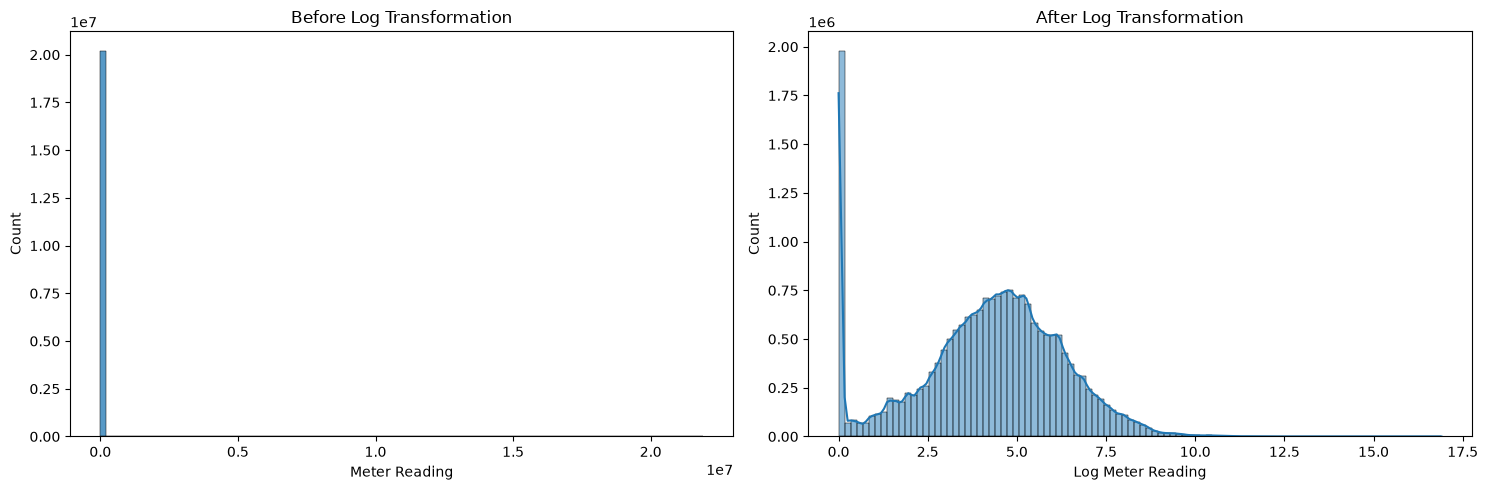

In [31]:
# Apply logarithmic transformation
train['meter_reading_log'] = np.log1p(train['meter_reading'])

# Plot distributions before and after transformation
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Before transformation
sns.histplot(train['meter_reading'], bins=100, ax=ax[0], kde=False)
ax[0].set_title('Before Log Transformation')
ax[0].set_xlabel('Meter Reading')

# After transformation
sns.histplot(train['meter_reading_log'], bins=100, ax=ax[1], kde=True)
ax[1].set_title('After Log Transformation')
ax[1].set_xlabel('Log Meter Reading')

plt.tight_layout()
plt.show()

In [25]:
print('Skewness before:', train['meter_reading'].skew())
print('Skewness after:', train['meter_reading_log'].skew())

Skewness before: 104.81131369454786
Skewness after: -0.2753768424199096


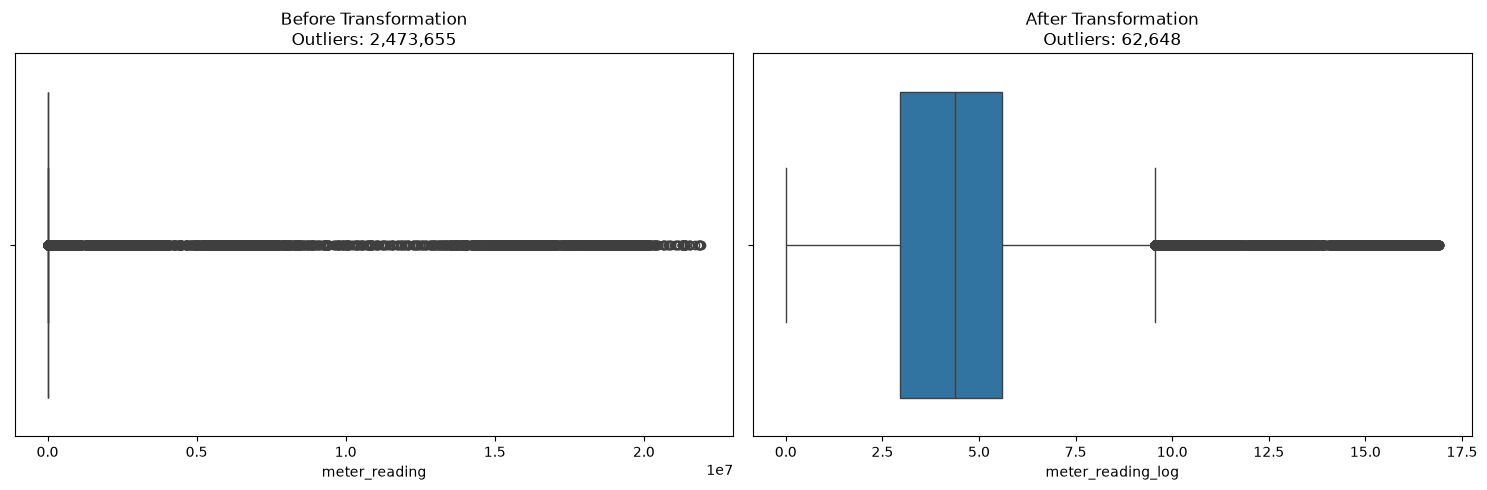

In [26]:
# Function to count outliers using IQR
def count_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) | (data > upper_bound)
    ]

    return len(outliers)


# Calculate number of outliers
before = count_outliers(train['meter_reading'])
after = count_outliers(train['meter_reading_log'])

# Plot boxplots
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x=train['meter_reading'], ax=ax[0])
ax[0].set_title(f'Before Transformation\nOutliers: {before:,}')

sns.boxplot(x=train['meter_reading_log'], ax=ax[1])
ax[1].set_title(f'After Transformation\nOutliers: {after:,}')

plt.tight_layout()
plt.show()

In [27]:
outlier_summary = pd.DataFrame({
    'Transformation': ['Before', 'After'],
    'Number of Outliers': [before, after],
    'Outliers (%)': [
        before / len(train) * 100,
        after / len(train) * 100
    ]
})

outlier_summary.round(2)

,Transformation,Number of Outliers,Outliers (%)
0,Before,2473655,12.24
1,After,62648,0.31


### 2. correlation analysis

In [32]:
# # Convert timestamps
train['timestamp'] = pd.to_datetime(train['timestamp'])
weather_train['timestamp'] = pd.to_datetime(weather_train['timestamp'])

# Merge datasets
df = (
    train
    .merge(building_metadata,
           on='building_id',
           how='left',
           validate='many_to_one')
    .merge(weather_train,
           on=['site_id', 'timestamp'],
           how='left',
           validate='many_to_one')
)

print(df.shape)
df.head()

(20216100, 17)


,building_id,meter,timestamp,meter_reading,meter_reading_log,site_id,primary_use,square_feet,year_built,floor_count,air_temperature,cloud_coverage,dew_temperature,precip_depth_1_hr,sea_level_pressure,wind_direction,wind_speed
0,0,0,2016-01-01,0.0,0.0,0,Education,7432,2008.0,NaN,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
1,1,0,2016-01-01,0.0,0.0,0,Education,2720,2004.0,NaN,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
2,2,0,2016-01-01,0.0,0.0,0,Education,5376,1991.0,NaN,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
3,3,0,2016-01-01,0.0,0.0,0,Education,23685,2002.0,NaN,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
4,4,0,2016-01-01,0.0,0.0,0,Education,116607,1975.0,NaN,25.0,6.0,20.0,NaN,1019.7,0.0,0.0


In [33]:
# Select numerical features
num_cols = [
    'square_feet',
    'year_built',
    'floor_count',
    'air_temperature',
    'cloud_coverage',
    'dew_temperature',
    'precip_depth_1_hr',
    'sea_level_pressure',
    'wind_speed',
    'meter_reading'
]

# Calculate Pearson correlation
corr_matrix = df[num_cols].corr(method='pearson')

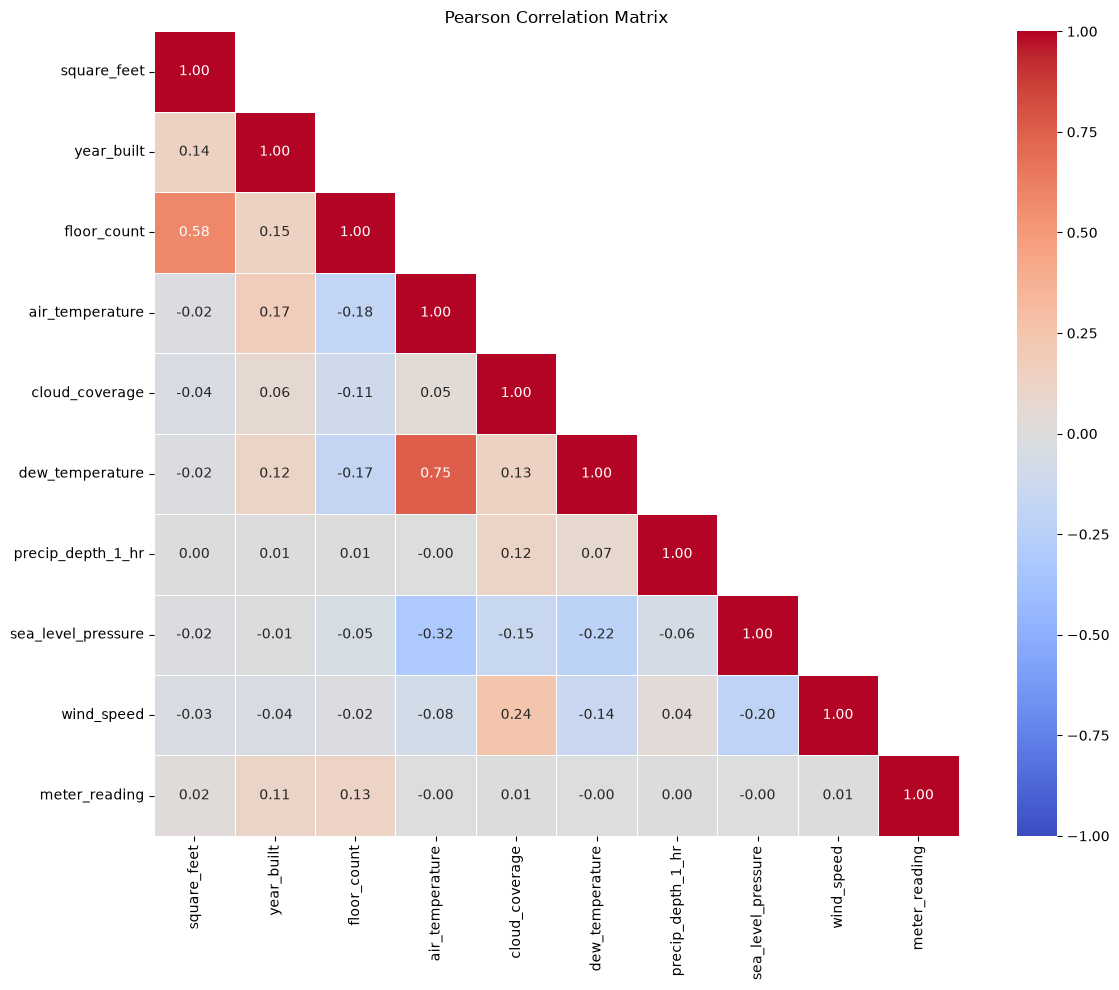

In [36]:
plt.figure(figsize=(13, 10))

mask = np.triu(
    np.ones_like(corr_matrix, dtype=bool),
    k=1
)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title('Pearson Correlation Matrix')
plt.tight_layout()
plt.show()

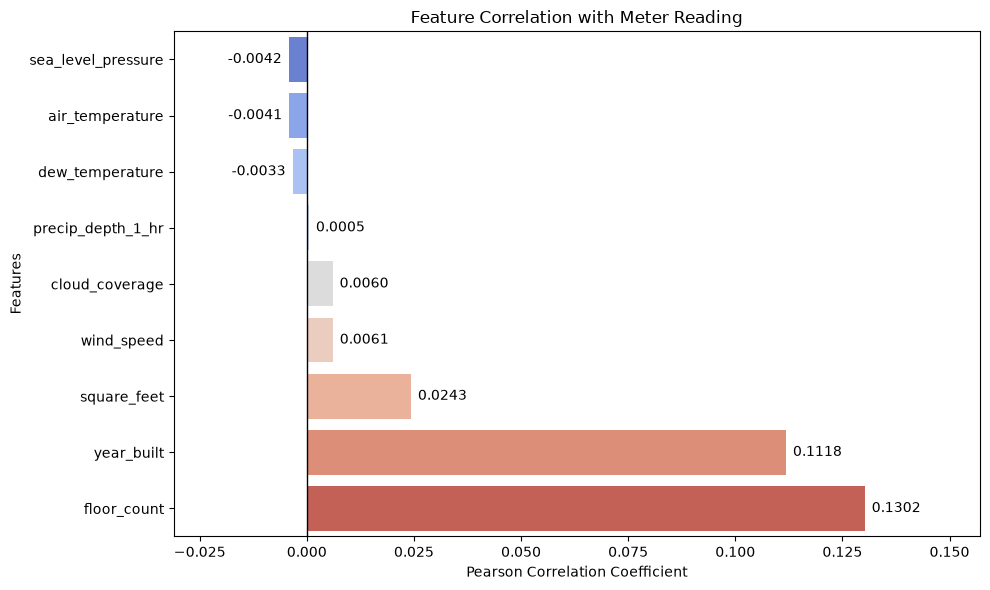

In [41]:
# Extract correlation with the target variable
target_corr = (
    corr_matrix['meter_reading']
    .drop('meter_reading')
    .sort_values()
)
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    hue=target_corr.index,
    palette='coolwarm',
    legend=False
)

# Display correlation value for each feature
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.4f',
        padding=5,
        fontsize=10
    )

plt.axvline(x=0, color='black', linewidth=1)
plt.margins(x=0.2)

plt.title('Feature Correlation with Meter Reading')
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### 3. categorical feature analysis

In [37]:
cat_features = {
    'train': ['meter'],
    'building_metadata': ['primary_use'],
    'weather_train': ['cloud_coverage']
}

datasets = {
    'train': train,
    'building_metadata': building_metadata,
    'weather_train': weather_train
}

summary = []

for dataset_name, columns in cat_features.items():

    data = datasets[dataset_name]

    for col in columns:
        summary.append({
            'Dataset': dataset_name,
            'Feature': col,
            'Number of Unique Values': data[col].nunique(),
            'Unique Values': data[col].dropna().unique().tolist()
        })

categorical_summary = pd.DataFrame(summary)

categorical_summary

,Dataset,Feature,Number of Unique Values,Unique Values
0,train,meter,4,"[0, 3, 1, 2]"
1,building_metadata,primary_use,16,"[Education, Lodging/residential, Office, Enter..."
2,weather_train,cloud_coverage,10,"[6.0, 2.0, 4.0, 8.0, 0.0, 9.0, 7.0, 5.0, 3.0, ..."


In [38]:
for dataset_name, columns in cat_features.items():

    data = datasets[dataset_name]

    for col in columns:

        print(f'\nDataset: {dataset_name}')
        print(f'Feature: {col}')

        frequency = pd.DataFrame({
            'Count': data[col].value_counts(),
            'Percentage (%)': data[col].value_counts(normalize=True) * 100
        })

        display(frequency.round(2))


Dataset: train
Feature: meter


,Count,Percentage (%)
meter,,
0,12060910,59.66
1,4182440,20.69
2,2708713,13.40
3,1264037,6.25



Dataset: building_metadata
Feature: primary_use


,Count,Percentage (%)
primary_use,,
Education,549,37.89
Office,279,19.25
Entertainment/public assembly,184,12.70
Public services,156,10.77
Lodging/residential,147,10.14
Other,25,1.73
Healthcare,23,1.59
Parking,22,1.52
Warehouse/storage,13,0.90



Dataset: weather_train
Feature: cloud_coverage


,Count,Percentage (%)
cloud_coverage,,
0.0,33871,47.98
2.0,13585,19.24
4.0,10241,14.51
8.0,3531,5.00
6.0,3521,4.99
7.0,3485,4.94
1.0,713,1.01
3.0,608,0.86
5.0,526,0.75


In [39]:
meter_labels = {
    0: 'Electricity',
    1: 'Chilled Water',
    2: 'Steam',
    3: 'Hot Water'
}

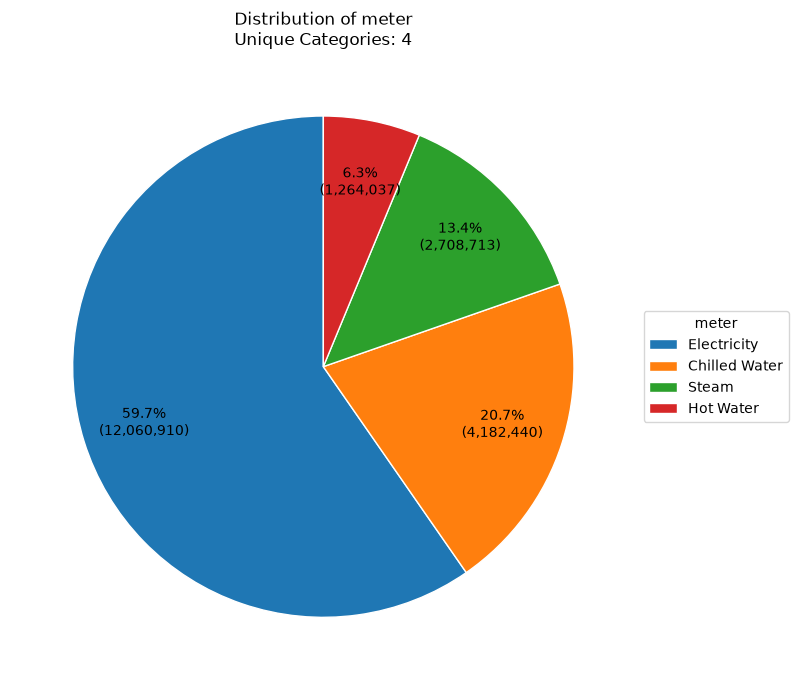

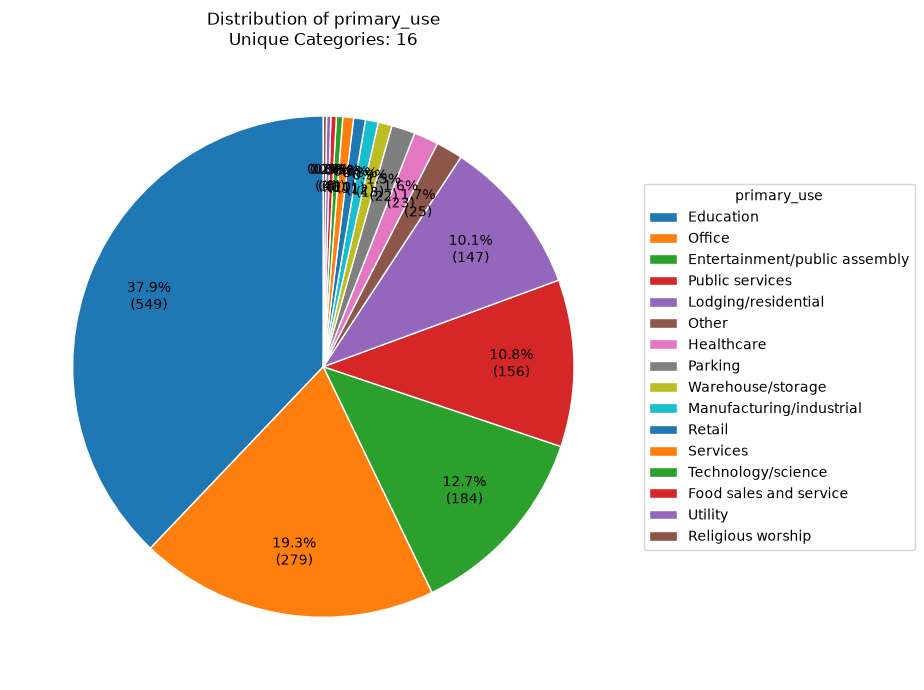

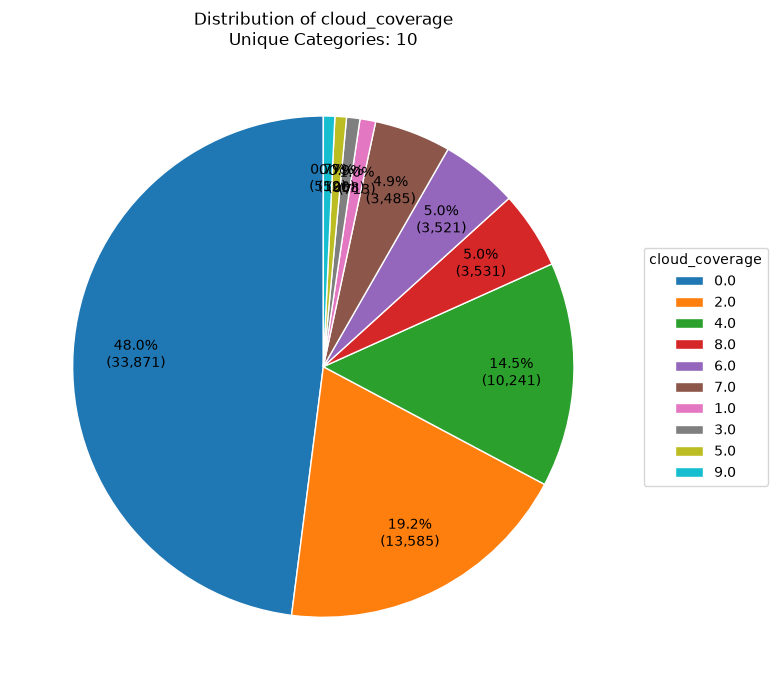

In [40]:
# Function to display percentage and count
def pie_label(pct, total):
    count = int(round(pct / 100 * total))
    return f'{pct:.1f}%\n({count:,})'


for dataset_name, columns in cat_features.items():

    data = datasets[dataset_name]

    for col in columns:

        counts = data[col].value_counts()

        # Replace meter codes with actual names
        if col == 'meter':
            counts = counts.rename(index=meter_labels)

        plt.figure(figsize=(10, 7))

        plt.pie(
            counts.values,
            autopct=lambda pct: pie_label(pct, counts.sum()),
            startangle=90,
            pctdistance=0.75,
            wedgeprops={'edgecolor': 'white'}
        )

        plt.legend(
            counts.index.astype(str),
            title=col,
            loc='center left',
            bbox_to_anchor=(1, 0.5)
        )

        plt.title(
            f'Distribution of {col}\n'
            f'Unique Categories: {len(counts)}'
        )

        plt.tight_layout()
        plt.show()

## understanding the data

In [19]:
for i in train.columns.tolist():
    print(i, ':', train[i].isnull().mean())

building_id : 0.0
meter : 0.0
timestamp : 0.0
meter_reading : 0.0
meter_reading_log : 0.0


In [18]:
for i in building_metadata.columns.tolist():
    print(i, ':', building_metadata[i].isnull().mean())

site_id : 0.0
building_id : 0.0
primary_use : 0.0
square_feet : 0.0
year_built : 0.5341614906832298
floor_count : 0.7550034506556246


In [22]:
for i in weather_train.columns.tolist():
    print(i, ':', weather_train[i].isnull().mean())

site_id : 0.0
timestamp : 0.0
air_temperature : 0.0003934951671639015
cloud_coverage : 0.4948952945132465
dew_temperature : 0.0008084537070821976
precip_depth_1_hr : 0.3597905174819171
sea_level_pressure : 0.07596603063538737
wind_direction : 0.04484414014151517
wind_speed : 0.0021749551057786555


In [6]:
print(len(train['timestamp'][train['timestamp'] == '2016-01-01 00:00:00']))
print(train.shape)
print(train['building_id'].nunique())

2301
(20216100, 4)
1449


In [15]:
train['timestamp'] = pd.to_datetime(train['timestamp'])
weather_train['timestamp'] = pd.to_datetime(weather_train['timestamp'])

weather_train['timestamp'].describe()

count                        139773
mean     2016-07-02 07:17:57.942091
min             2016-01-01 00:00:00
25%             2016-04-02 02:00:00
50%             2016-07-02 09:00:00
75%             2016-10-01 16:00:00
max             2016-12-31 23:00:00
Name: timestamp, dtype: object

In [17]:
train['timestamp'].head()

0   2016-01-01
1   2016-01-01
2   2016-01-01
3   2016-01-01
4   2016-01-01
Name: timestamp, dtype: datetime64[us]

In [23]:
print('building_metadata shape',building_metadata.shape)
print('train shape',train.shape)
print('weather_train shape' ,weather_train.shape)

print('building_metadata columns:' ,building_metadata.columns)
print('train columns:' ,train.columns)
print('weather_train columns:', weather_train.columns)

# print(building_metadata.shape)
# print(building_metadata.shape)
# print(building_metadata.shape)

building_metadata shape (1449, 6)
train shape (20216100, 5)
weather_train shape (139773, 9)
building_metadata columns: Index(['site_id', 'building_id', 'primary_use', 'square_feet', 'year_built',
       'floor_count'],
      dtype='str')
train columns: Index(['building_id', 'meter', 'timestamp', 'meter_reading',
       'meter_reading_log'],
      dtype='str')
weather_train columns: Index(['site_id', 'timestamp', 'air_temperature', 'cloud_coverage',
       'dew_temperature', 'precip_depth_1_hr', 'sea_level_pressure',
       'wind_direction', 'wind_speed'],
      dtype='str')


In [18]:
train.isnull().mean()

,0
building_id,0.000000e+00
meter,0.000000e+00
timestamp,7.539697e-08
meter_reading,7.539697e-08


count    1.326313e+07
mean     2.903310e+03
std      1.866738e+05
min      0.000000e+00
25%      1.757810e+01
50%      7.685000e+01
75%      2.630000e+02
max      2.190470e+07
Name: meter_reading, dtype: float64
Skewness: 85.93980393299887


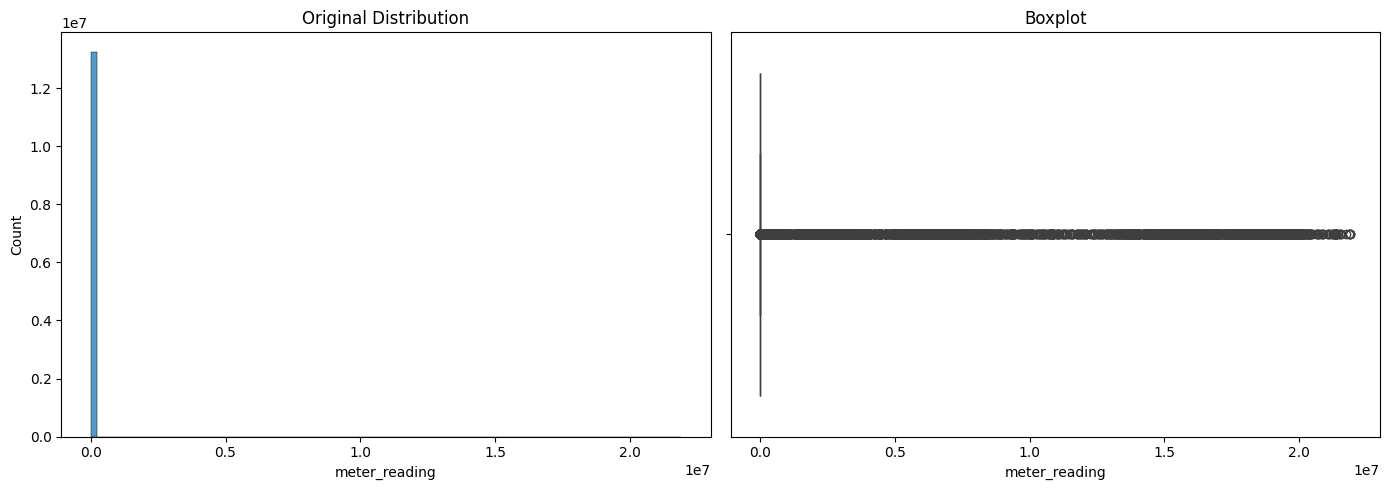

In [16]:
# print(train.shape)
# train['meter_reading'].value_counts()
# train['meter_reading'].max()

print(train['meter_reading'].describe())

print("Skewness:", train['meter_reading'].skew())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train['meter_reading'], bins=100, ax=axes[0])
axes[0].set_title('Original Distribution')

sns.boxplot(x=train['meter_reading'], ax=axes[1])
axes[1].set_title('Boxplot')

plt.tight_layout()
plt.show()

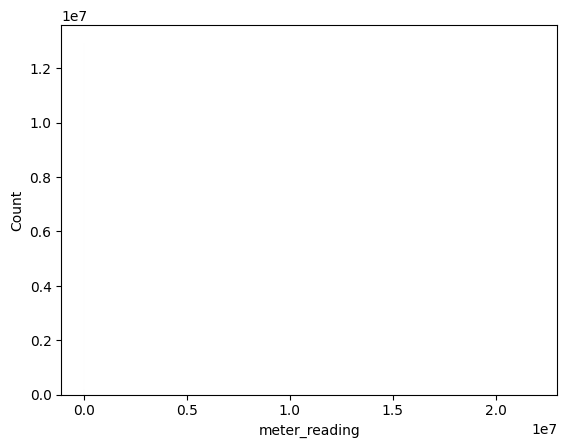

In [10]:
sns.histplot(train['meter_reading'])
plt.show()